### Imports and paths

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("../data/raw")
PROC_DIR = Path("../data/processed"); PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR  = Path("../figures");        FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)

### Sensor names

In [2]:
sensor_map = {
    "s1": "T2_fan_inlet_temp", "s2": "T24_LPC_outlet_temp", "s3": "T30_HPC_outlet_temp",
    "s4": "T50_LPT_outlet_temp", "s5": "P2_fan_inlet_pressure", "s6": "P15_bypass_duct_pressure",
    "s7": "P30_HPC_outlet_pressure", "s8": "Nf_fan_speed", "s9": "Nc_core_speed",
    "s10": "epr_engine_pressure_ratio", "s11": "Ps30_HPC_static_pressure",
    "s12": "phi_fuel_flow_to_Ps30", "s13": "NRf_corrected_fan_speed",
    "s14": "NRc_corrected_core_speed", "s15": "BPR_bypass_ratio",
    "s16": "farB_burner_fuel_air_ratio", "s17": "htBleed_bleed_enthalpy",
    "s18": "Nf_dmd_demanded_fan_speed", "s19": "PCNfR_dmd_demanded_corr_fan_speed",
    "s20": "W31_HPT_coolant_bleed", "s21": "W32_LPT_coolant_bleed",
}
cols = ["unit", "cycle", "op1", "op2", "op3"] + list(sensor_map)

### Load the data and add RUL

In [3]:
df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=cols)

RUL_CAP = 125
df["RUL"]     = df.groupby("unit")["cycle"].transform("max") - df["cycle"]
df["RUL_cap"] = df["RUL"].clip(upper=RUL_CAP)

print("Shape:", df.shape, "| engines:", df["unit"].nunique())

Shape: (20631, 28) | engines: 100


### Apply sensor selection rule

In [4]:
sensors = list(sensor_map)
std  = df[sensors].std()
nuni = df[sensors].nunique()

keep = [s for s in sensors if std[s] >= 1e-6 and nuni[s] >= 3]
EXP4_KEEP = ["s2","s3","s4","s7","s8","s9","s11","s12","s13","s14","s15","s17","s20","s21"]

assert keep == EXP4_KEEP, "Sensor set differs from Experiment 4!"
print("Kept", len(keep), "sensors:", keep)

Kept 14 sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


### Why covariance-based PCA would mislead

In [6]:
X = df[keep].to_numpy(dtype=float, copy=True)
n, p = X.shape

var = pd.Series(X.var(axis=0, ddof=1), index=keep)
share = (var / var.sum() * 100).sort_values(ascending=False)

print(f"n = {n}, p = {p}")
print("Share of TOTAL raw variance (%):")
print(share.round(2))
print(f"\ns9 + s14 together: {share[['s9','s14']].sum():.1f}% of total variance")

n = 20631, p = 14
Share of TOTAL raw variance (%):
s9     50.05
s14    37.35
s4      8.32
s3      3.86
s17     0.25
s7      0.08
s12     0.06
s2      0.03
s11     0.01
s20     0.00
s21     0.00
s13     0.00
s8      0.00
s15     0.00
dtype: float64

s9 + s14 together: 87.4% of total variance


#### Teaching point: 

Look at how much of the total raw variance comes from s9 and s14 together. If that share is large, covariance-based PCA would make PC1 essentially "core speed", and Experiment 4 showed those are the weakest RUL trackers (|r| = 0.46 and 0.37). That's a units effect, not physics.

### Standardise by hand and check against scikit-learn

In [7]:
mu    = X.mean(axis=0)
sigma = X.std(axis=0, ddof=1)          # sample std, as in Exp 4
Z     = (X - mu) / sigma

Z_sk = StandardScaler().fit_transform(X)   # uses ddof = 0 (population std)

ratio = Z / Z_sk
print("Z / Z_sklearn  min, max :", ratio.min().round(8), ratio.max().round(8))
print("sqrt((n-1)/n)           :", round(np.sqrt((n - 1) / n), 8))

Z / Z_sklearn  min, max : 0.99997576 0.99997576
sqrt((n-1)/n)           : 0.99997576


#### Teaching point: 

StandardScaler divides by n, not n−1, so the two versions differ by a constant factor sqrt{(n-1)/n} = 0.99998. Scaling every column by the same constant doesn't change any eigenvector, so the principal directions are identical. Only the eigenvalues are scaled by (n−1)/n.

### Check that cov(Z) = R

In [8]:
R_from_Z = (Z.T @ Z) / (n - 1)
R_pandas = df[keep].corr().to_numpy()

print("Column means ~0   :", np.allclose(Z.mean(axis=0), 0))
print("Column stds = 1   :", np.allclose(Z.std(axis=0, ddof=1), 1))
print("max |Z'Z/(n-1) - R|:", np.abs(R_from_Z - R_pandas).max())
print("trace             :", np.trace(R_from_Z).round(6), "(= p)")

Column means ~0   : True
Column stds = 1   : True
max |Z'Z/(n-1) - R|: 9.285822111237962e-12
trace             : 14.0 (= p)


### Save the clean data and Z for later steps

In [9]:
clean = df[["unit", "cycle", "RUL", "RUL_cap"] + keep].copy()
clean.to_csv(PROC_DIR / "fd001_clean.csv", index=False)

np.save(PROC_DIR / "Z.npy", Z)
pd.Series(mu, index=keep).to_csv(PROC_DIR / "mu.csv")
pd.Series(sigma, index=keep).to_csv(PROC_DIR / "sigma.csv")
print("Saved:", clean.shape, Z.shape)

Saved: (20631, 18) (20631, 14)


### Eigen-decomposition of R

In [10]:
R = (Z.T @ Z) / (n - 1)

eigvals, eigvecs = np.linalg.eigh(R)          # eigh: symmetric matrix, ascending order
order   = np.argsort(eigvals)[::-1]           # sort descending
lam     = eigvals[order]
V       = eigvecs[:, order]

pc_names = [f"PC{k+1}" for k in range(p)]
pd.DataFrame({"eigenvalue": lam,
              "var_%": lam / lam.sum() * 100,
              "cum_%": np.cumsum(lam) / lam.sum() * 100},
             index=pc_names).round(3)

,eigenvalue,var_%,cum_%
PC1,8.995,64.251,64.251
PC2,2.096,14.971,79.222
PC3,0.414,2.958,82.179
PC4,0.368,2.631,84.810
PC5,0.348,2.488,87.298
PC6,0.306,2.187,89.485
PC7,0.290,2.070,91.555
PC8,0.255,1.824,93.380
PC9,0.206,1.473,94.853
PC10,0.196,1.400,96.253


Why sort: eigh returns eigenvalues in ascending order. PCA needs the largest first.

### Check the spectral theorem

In [11]:
Lam = np.diag(lam)

print("R v = λ v (all k)     :", np.allclose(R @ V, V @ Lam))
print("V orthonormal (V'V=I) :", np.allclose(V.T @ V, np.eye(p)))
print("R = V Λ V'            :", np.allclose(V @ Lam @ V.T, R))
print("sum λ  = trace(R)     :", lam.sum().round(6))
print("prod λ = det(R)       :", f"{np.prod(lam):.3e}", "vs", f"{np.linalg.det(R):.3e}")
print("λ_min, λ_max          :", lam.min().round(5), lam.max().round(5))
print("Condition number κ(R) :", (lam.max() / lam.min()).round(1))

R v = λ v (all k)     : True
V orthonormal (V'V=I) : True
R = V Λ V'            : True
sum λ  = trace(R)     : 14.0
prod λ = det(R)       : 1.197e-07 vs 1.197e-07
λ_min, λ_max          : 0.02927 8.99508
Condition number κ(R) : 307.3


### The SVD route

In [12]:
U, svals, Vt = np.linalg.svd(Z, full_matrices=False)
lam_svd = svals**2 / (n - 1)
V_svd   = Vt.T

print("max |λ_eig - λ_svd|           :", np.abs(lam - lam_svd).max())
# eigenvectors are unique only up to sign -> compare |dot product|
align = np.abs(np.sum(V * V_svd, axis=0))
print("|v_eig · v_svd| per component :", align.round(6))

max |λ_eig - λ_svd|           : 3.552713678800501e-15
|v_eig · v_svd| per component : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


#### Teaching point: 

Each ∣veig⋅vsvd∣should be 1. Some raw dot products are −1, because if v is an eigenvector, so is −v. The sign of a principal component is arbitrary. Engineers need to know this before they interpret a loading or build a health index.

### Check against scikit-learn

In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=p).fit(Z)

print("max |λ - sklearn explained_variance_| :", np.abs(lam - pca.explained_variance_).max())
print("explained_variance_ratio_ sum         :", pca.explained_variance_ratio_.sum().round(6))
align_sk = np.abs(np.sum(V * pca.components_.T, axis=0))
print("|v_eig · v_sklearn| per component     :", align_sk.round(6))

max |λ - sklearn explained_variance_| : 0.0
explained_variance_ratio_ sum         : 1.0
|v_eig · v_sklearn| per component     : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Fix a sign convention

In [14]:
# Convention: the largest-magnitude loading of each PC is positive
flip = np.sign(V[np.argmax(np.abs(V), axis=0), np.arange(p)])
V = V * flip

loadings = pd.DataFrame(V, index=keep, columns=pc_names)
loadings.iloc[:, :3].round(3)

,PC1,PC2,PC3
s2,0.273,0.017,-0.188
s3,0.260,0.076,0.935
s4,0.301,0.009,-0.035
s7,-0.298,0.053,0.029
s8,0.282,-0.244,-0.020
s9,0.106,0.644,-0.046
s11,0.309,-0.016,-0.034
s12,-0.304,0.063,0.021
s13,0.281,-0.246,-0.023
s14,0.066,0.667,-0.041


### Scores, and checking they're uncorrelated


In [15]:
T = Z @ V                                   # principal component scores
C_T = (T.T @ T) / (n - 1)

print("var(scores) = λ          :", np.allclose(np.diag(C_T), lam))
print("scores uncorrelated      :", np.allclose(C_T - np.diag(np.diag(C_T)), 0, atol=1e-10))
print("max |off-diagonal cov|   :", f"{np.abs(C_T - np.diag(np.diag(C_T))).max():.2e}")

np.save(PROC_DIR / "V.npy", V)
np.save(PROC_DIR / "lam.npy", lam)
np.save(PROC_DIR / "T.npy", T)

var(scores) = λ          : True
scores uncorrelated      : True
max |off-diagonal cov|   : 2.89e-15


### Teaching point: 

PCA rotates 14 correlated sensors into 14 uncorrelated components. The heatmap of cov⁡(T) would be diagonal, which is the opposite of the Experiment 4 heatmap with its red and blue blocks.

### Scree plot and cumulative variance

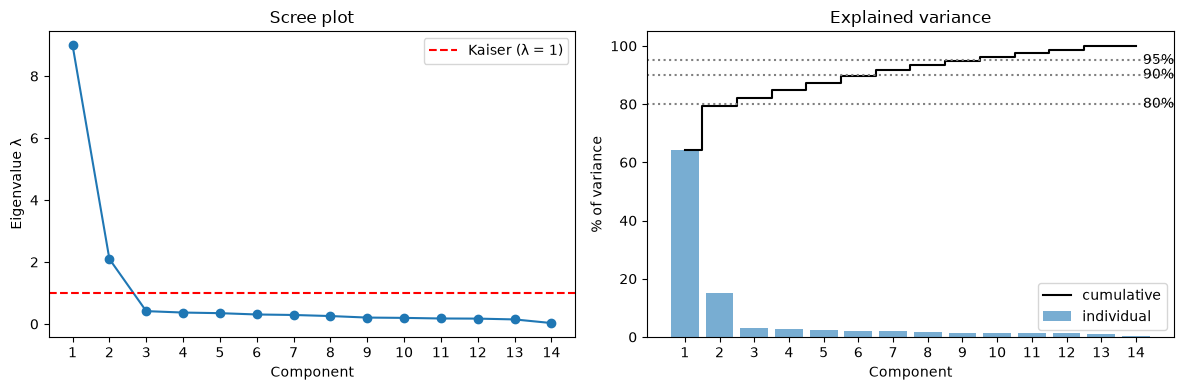

In [16]:
var_pct = lam / lam.sum() * 100
cum_pct = np.cumsum(var_pct)
k_axis  = np.arange(1, p + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_axis, lam, "o-")
ax[0].axhline(1, color="red", ls="--", label="Kaiser (λ = 1)")
ax[0].set_xlabel("Component"); ax[0].set_ylabel("Eigenvalue λ")
ax[0].set_title("Scree plot"); ax[0].set_xticks(k_axis); ax[0].legend()

ax[1].bar(k_axis, var_pct, alpha=0.6, label="individual")
ax[1].step(k_axis, cum_pct, where="mid", color="k", label="cumulative")
for t in (80, 90, 95):
    ax[1].axhline(t, ls=":", color="grey"); ax[1].text(p + 0.2, t, f"{t}%", va="center")
ax[1].set_xlabel("Component"); ax[1].set_ylabel("% of variance")
ax[1].set_title("Explained variance"); ax[1].set_xticks(k_axis); ax[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_scree_cumulative.png", dpi=150)
plt.show()

### Broken stick and parallel analysis

In [17]:
# Broken stick
b = np.array([np.sum(1 / np.arange(k, p + 1)) / p for k in range(1, p + 1)]) * 100

# Parallel analysis: shuffle each column independently, recompute eigenvalues
rng = np.random.default_rng(42)
N_REP = 50
lam_rand = np.empty((N_REP, p))
for r in range(N_REP):
    Zs = np.column_stack([rng.permutation(Z[:, j]) for j in range(p)])
    lam_rand[r] = np.sort(np.linalg.eigvalsh((Zs.T @ Zs) / (n - 1)))[::-1]
lam_95 = np.percentile(lam_rand, 95, axis=0)

rules = pd.DataFrame({"λ": lam, "var_%": var_pct, "cum_%": cum_pct,
                      "broken_stick_%": b, "parallel_95%_λ": lam_95},
                     index=pc_names).round(3)
rules["Kaiser"]   = lam > 1
rules["BrokenSt"] = var_pct > b
rules["Parallel"] = lam > lam_95
rules

,λ,var_%,cum_%,broken_stick_%,parallel_95%_λ,Kaiser,BrokenSt,Parallel
PC1,8.995,64.251,64.251,23.225,1.052,True,True,True
PC2,2.096,14.971,79.222,16.083,1.039,True,False,True
PC3,0.414,2.958,82.179,12.511,1.032,False,False,False
PC4,0.368,2.631,84.810,10.130,1.024,False,False,False
PC5,0.348,2.488,87.298,8.344,1.019,False,False,False
PC6,0.306,2.187,89.485,6.916,1.013,False,False,False
PC7,0.290,2.070,91.555,5.725,1.007,False,False,False
PC8,0.255,1.824,93.380,4.705,1.000,False,False,False
PC9,0.206,1.473,94.853,3.812,0.995,False,False,False
PC10,0.196,1.400,96.253,3.019,0.990,False,False,False


Why shuffle: shuffling each column separately keeps every sensor's distribution but destroys all correlation between sensors. Any eigenvalue that doesn't beat the shuffled version is just what you'd get by chance.

### Summary of the selection rules

In [18]:
def first_k(cond):            # number of leading components that satisfy cond
    return int(np.argmin(cond)) if not cond.all() else p

summary = pd.Series({
    "Kaiser (λ > 1)":         first_k(rules["Kaiser"].to_numpy()),
    "Broken stick":           first_k(rules["BrokenSt"].to_numpy()),
    "Parallel analysis":      first_k(rules["Parallel"].to_numpy()),
    "80% cumulative":         int(np.argmax(cum_pct >= 80) + 1),
    "90% cumulative":         int(np.argmax(cum_pct >= 90) + 1),
    "95% cumulative":         int(np.argmax(cum_pct >= 95) + 1),
}, name="k")
summary

Kaiser (λ > 1)        2
Broken stick          1
Parallel analysis     2
80% cumulative        3
90% cumulative        7
95% cumulative       10
Name: k, dtype: int64

### Reconstruction error, checking Eckart–Young

In [19]:
rows = []
for k in range(1, p + 1):
    Zk  = T[:, :k] @ V[:, :k].T
    err = np.sum((Z - Zk) ** 2) / (n - 1)
    rows.append({"k": k, "recon_error": err, "sum_dropped_λ": lam[k:].sum()})
recon = pd.DataFrame(rows).set_index("k")
print("Eckart–Young holds:", np.allclose(recon["recon_error"], recon["sum_dropped_λ"]))
recon.round(4)

Eckart–Young holds: True


,recon_error,sum_dropped_λ
k,,
1,5.0049,5.0049
2,2.9090,2.9090
3,2.4949,2.4949
4,2.1266,2.1266
5,1.7782,1.7782
6,1.4721,1.4721
7,1.1822,1.1822
8,0.9268,0.9268
9,0.7206,0.7206


### The smallest component, where near-collinearity comes from

In [20]:
v14 = pd.Series(V[:, -1], index=keep).sort_values(key=np.abs, ascending=False)
print(f"PC14: λ = {lam[-1]:.5f}  (variance of this sensor combination)")
v14.round(3)

PC14: λ = 0.02927  (variance of this sensor combination)


s9     0.713
s14   -0.701
s8    -0.017
s12    0.015
s13   -0.015
s11   -0.013
s21    0.009
s4    -0.009
s7     0.007
s15   -0.005
s20    0.003
s17   -0.003
s2    -0.003
s3    -0.001
dtype: float64

### Save

In [21]:
rules.to_csv(PROC_DIR / "pca_k_selection.csv")
recon.to_csv(PROC_DIR / "pca_reconstruction_error.csv")

### Loading bar plots for PC1 and PC2

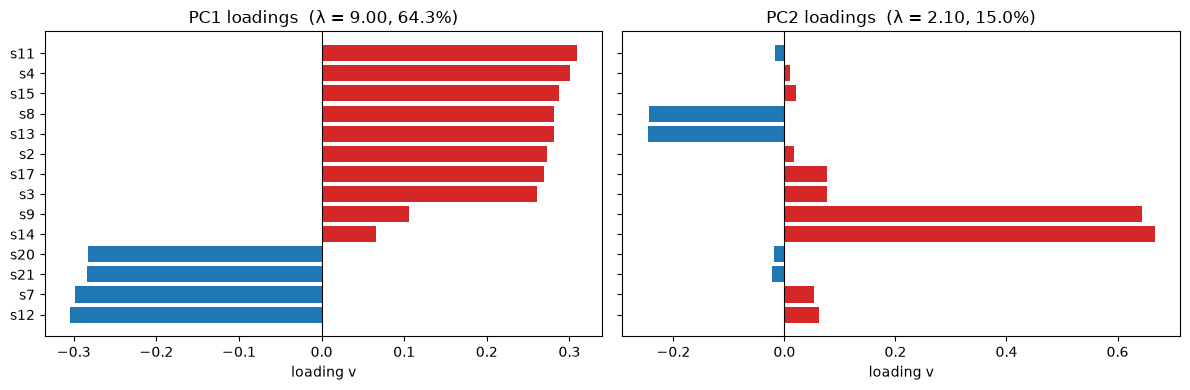

In [22]:
K = 2
fig, axes = plt.subplots(1, K, figsize=(12, 4), sharey=True)
for k, ax in enumerate(axes):
    v = loadings[pc_names[k]].sort_values()
    ax.barh(v.index, v.values, color=["tab:blue" if x < 0 else "tab:red" for x in v.values])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{pc_names[k]} loadings  (λ = {lam[k]:.2f}, {var_pct[k]:.1f}%)")
    ax.set_xlabel("loading v")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig02_loadings_pc1_pc2.png", dpi=150)
plt.show()

### Correlation loadings and communalities

In [23]:
corr_load = loadings.iloc[:, :K] * np.sqrt(lam[:K])
corr_load.columns = [f"r_{c}" for c in corr_load.columns]

# check against the direct correlation between each z_j and each score t_k
direct = np.array([[np.corrcoef(Z[:, j], T[:, k])[0, 1] for k in range(K)] for j in range(p)])
print("max |v√λ - corr(z, t)| :", np.abs(corr_load.to_numpy() - direct).max())

corr_load["communality_k2"] = (corr_load ** 2).sum(axis=1)
corr_load["name"] = [sensor_map[s] for s in keep]
corr_load.sort_values("communality_k2").round(3)

max |v√λ - corr(z, t)| : 7.771561172376096e-16


,r_PC1,r_PC2,communality_k2,name
s3,0.780,0.110,0.621,T30_HPC_outlet_temp
s17,0.808,0.112,0.665,htBleed_bleed_enthalpy
s2,0.820,0.025,0.673,T24_LPC_outlet_temp
s20,-0.848,-0.026,0.720,W31_HPT_coolant_bleed
s21,-0.851,-0.033,0.725,W32_LPT_coolant_bleed
s15,0.861,0.030,0.742,BPR_bypass_ratio
s7,-0.895,0.076,0.807,P30_HPC_outlet_pressure
s4,0.903,0.014,0.816,T50_LPT_outlet_temp
s13,0.844,-0.357,0.839,NRf_corrected_fan_speed
s8,0.845,-0.354,0.839,Nf_fan_speed


### Correlation circle

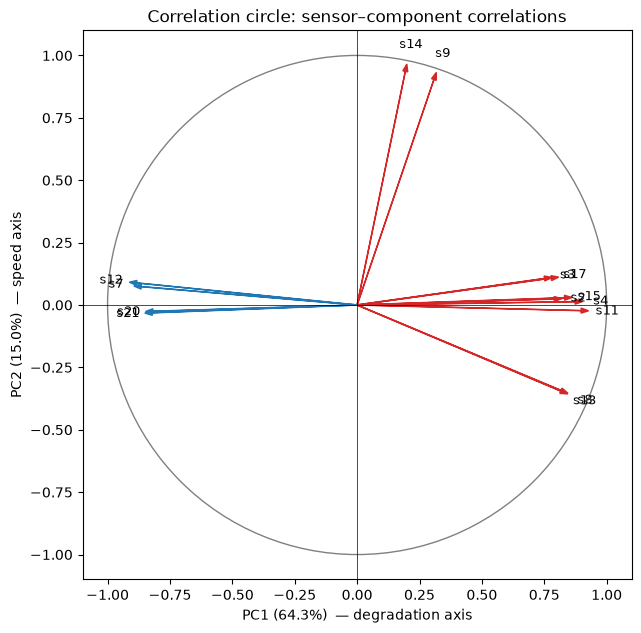

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for s, (x, y) in corr_load[["r_PC1", "r_PC2"]].iterrows():
    ax.arrow(0, 0, x, y, head_width=0.02, length_includes_head=True,
             color="tab:red" if x > 0 else "tab:blue")
    ax.text(x * 1.08, y * 1.08, s, fontsize=9, ha="center", va="center")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}%)  — degradation axis")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}%)  — speed axis")
ax.set_title("Correlation circle: sensor–component correlations")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_correlation_circle.png", dpi=150)
plt.show()

How to read it: the closer an arrow reaches the circle, the better the two components represent that sensor. Arrows pointing the same way are positively correlated sensors. Arrows pointing opposite ways are negatively correlated. Arrows at 90° are roughly uncorrelated.

### Biplot of scores coloured by RUL, with sensor arrows

### Which components track degradation?

### Save